# 7.1. Остывание стержня: устойчивость и точность

Температура в стержне единичной длины удовлетворяет уравнению теплопроводности
$$u_t=u_{xx},\qquad 0<x<1,\quad t>0,$$
$$u(0,t)=u(1,t)=0,\qquad u(x,0)=u_0(x).$$
Величины безразмерные, коэффициент температуропроводности равен единице. Источников тепла нет; концы стержня поддерживаются при нулевой температуре. Тепло перераспределяется вдоль стержня и уходит через концы, поэтому со временем он остывает.

Для гладкого начального распределения
$$u_0(x)=\sin(\pi x)+0.3\sin(5\pi x)$$
проверим явную схему FTCS и неявную схему Эйлера по известному точному решению. Затем рассмотрим равномерно нагретый участок $0.4\le x\le0.6$, добавим схему Кранка—Николсона и исследуем, что происходит около резких краёв при увеличении временного шага. В этой части основной вопрос — достаточно ли безусловной устойчивости, чтобы получить точный профиль без искусственных колебаний.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from scipy.linalg import solve_banded
from scipy.fft import dst, idst
from IPython.display import display, Markdown

plt.rcParams.update({
    'figure.dpi': 115,
    'font.size': 11,
    'axes.grid': True,
    'grid.alpha': 0.22,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

LABELS = {'FTCS': 'FTCS', 'BE': 'Неявный Эйлер', 'CN': 'Кранк—Николсон'}
STYLES = {
    'FTCS': dict(color='#0072B2', lw=3.2, ls='-', zorder=3),
    'BE': dict(color='#D55E00', lw=2.2, ls=(0, (5, 3)), zorder=4),
    'CN': dict(color='#009E73', lw=1.8, ls=(0, (4, 2, 1, 2)), zorder=5),
}
REFERENCE_STYLE = dict(color='black', lw=1.2, ls=(0, (1.2, 3)), zorder=6)


def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(map(str, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def plot_run(ax, run, t, label=True):
    method = run['method']
    return ax.plot(run['x'], at_time(run, t), **STYLES[method],
                   label=LABELS[method] if label else None)[0]


def plot_small_step(ax, t):
    return ax.plot(reference['x'], at_time(reference, t), **REFERENCE_STYLE,
                   label='Малый шаг')[0]


def shared_legend(fig, ax):
    fig.legend(*ax.get_legend_handles_labels(), loc='lower center',
               ncol=4, fontsize=10)

## 1. Точное решение и сглаживание температурного профиля

Для одной пространственной гармоники положим $u(x,t)=a_m(t)\sin(m\pi x)$. Она удовлетворяет нулевым граничным условиям. Подстановка в уравнение даёт
$$a_m'(t)=-(m\pi)^2a_m(t),\qquad
a_m(t)=a_m(0)e^{-(m\pi)^2t}.$$
Поскольку уравнение линейное, две гармоники затухают независимо:
$$u_*(x,t)=e^{-\pi^2t}\sin(\pi x)
+0.3e^{-25\pi^2t}\sin(5\pi x).$$

Характерное время, за которое амплитуда уменьшается в $e$ раз, равно $1/(m\pi)^2$. Для первой гармоники это примерно $0.1013$, для пятой — $0.00405$. Следовательно, мелкие детали исчезают быстрее крупных: при одинаковой амплитуде у короткой волны больше кривизна профиля, а скорость её затухания пропорциональна квадрату пространственной частоты.

К $t=0.01$ амплитуда пятой гармоники уменьшается с $0.3$ до $0.0254$, тогда как амплитуда первой — с $1$ до $0.906$. При $t=0.1$ пятая гармоника практически исчезает и профиль принимает форму одной полуволны синуса. Такое сглаживание присутствует в точном решении; само по себе оно не является численной ошибкой.

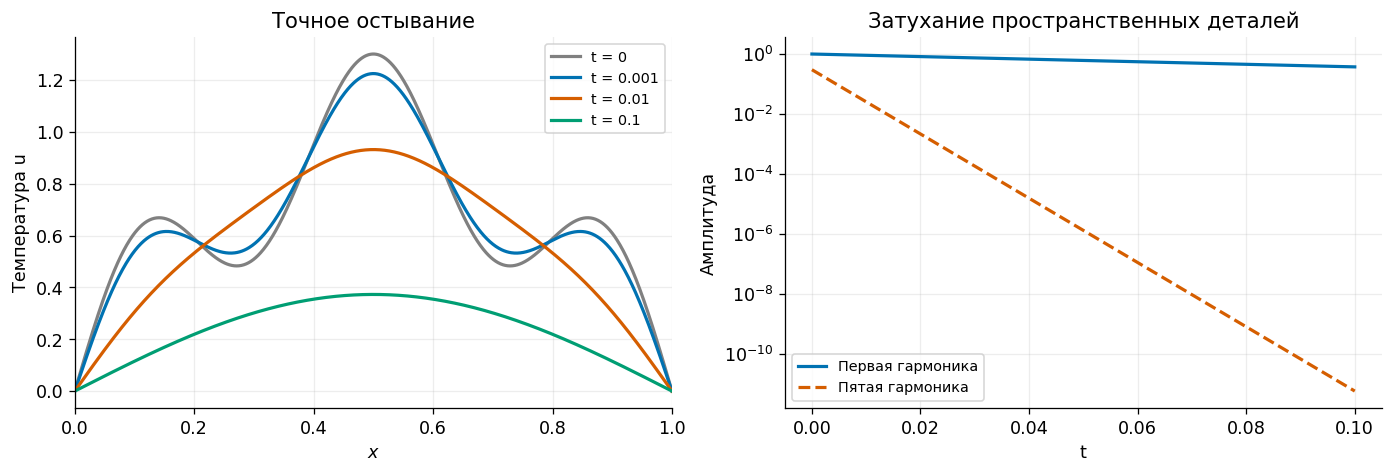

| t | Амплитуда первой гармоники | Амплитуда пятой гармоники |
| --- | --- | --- |
| 0.001 | 0.990179 | 2.344031e-01 |
| 0.01 | 0.906018 | 2.544149e-02 |
| 0.1 | 0.372708 | 5.772108e-12 |

In [2]:
def smooth_profile(x):
    return np.sin(np.pi * x) + 0.3 * np.sin(5 * np.pi * x)


def hot_section(x):
    return ((x >= 0.4) & (x <= 0.6)).astype(float)


def cooling_exact(x, t):
    return (np.exp(-np.pi**2 * t) * np.sin(np.pi * x)
            + 0.3 * np.exp(-25 * np.pi**2 * t) * np.sin(5 * np.pi * x))


target_times = [0.001, 0.01, 0.1]
xx = np.linspace(0, 1, 1001)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for t, color in zip([0.0] + target_times, ['0.5', '#0072B2', '#D55E00', '#009E73']):
    axes[0].plot(xx, cooling_exact(xx, t), color=color, lw=2, label=f't = {t:g}')
axes[0].set(xlabel='$x$', ylabel='Температура u', title='Точное остывание', xlim=(0, 1))
axes[0].legend(fontsize=9)
tt = np.linspace(0, 0.1, 501)
axes[1].semilogy(tt, np.exp(-np.pi**2 * tt), color='#0072B2', lw=2,
                 label='Первая гармоника')
axes[1].semilogy(tt, 0.3 * np.exp(-25 * np.pi**2 * tt), color='#D55E00',
                 lw=2, ls='--', label='Пятая гармоника')
axes[1].set(xlabel='t', ylabel='Амплитуда', title='Затухание пространственных деталей')
axes[1].legend(fontsize=9)
plt.show()

table(['t', 'Амплитуда первой гармоники', 'Амплитуда пятой гармоники'], [
    [f'{t:g}', f'{np.exp(-np.pi**2 * t):.6f}',
     f'{0.3 * np.exp(-25 * np.pi**2 * t):.6e}'] for t in target_times
])

## 2. Разностные схемы и проверка сходимости

Разобьём стержень на $N$ интервалов: $h=1/N$, $x_j=jh$, $j=0,\ldots,N$. Численную температуру в момент $t_n$ обозначим $U_j^n$. В крайних узлах $U_0^n=U_N^n=0$, поэтому на каждом слое нужно найти $N-1$ внутренних значений.

Вторую производную заменяем центральной разностью:
$$L_hU_j=\frac{U_{j-1}-2U_j+U_{j+1}}{h^2}.$$
Для гладкой функции её погрешность имеет порядок $h^2$. Обозначим фактический шаг времени через $\tau_n=t_{n+1}-t_n$ и введём $r_n=\tau_n/h^2$.

### Явная схема FTCS

Берём разность вперёд по времени и центральную разность по пространству на известном слое:
$$\frac{U_j^{n+1}-U_j^n}{\tau_n}=L_hU_j^n.$$
Отсюда
$$U_j^{n+1}=r_nU_{j-1}^n+(1-2r_n)U_j^n+r_nU_{j+1}^n.$$
При $0\le r_n\le1/2$ веса неотрицательны и в сумме равны единице. Новая температура лежит между наименьшим и наибольшим из трёх старых значений. Это обеспечивает устойчивость и сохранение диапазона температур. В явных расчётах используем $r=0.4$.

### Неявная схема Эйлера

Здесь пространственную производную берём на новом слое:
$$\frac{U_j^{n+1}-U_j^n}{\tau_n}=L_hU_j^{n+1},$$
$$-r_nU_{j-1}^{n+1}+(1+2r_n)U_j^{n+1}-r_nU_{j+1}^{n+1}=U_j^n.$$
Все внутренние температуры связаны трёхдиагональной системой. На главной диагонали стоят $1+2r_n$, на соседних — $-r_n$. Известные граничные значения нулевые, поэтому дополнительных слагаемых справа нет. Метод устойчив при любом $r_n>0$ и для этого оператора сохраняет диапазон температур.

Оба метода имеют погрешность $O(\tau+h^2)$ на гладком решении. В опыте сходимости фиксируем $r=0.4$:
$$\tau=0.4h^2,\qquad O(\tau+h^2)=O(h^2).$$
Ожидаемый второй порядок относится к **совместному уменьшению шагов**. По одному лишь времени обе схемы Эйлера остаются методами первого порядка.

В коде используется общая запись
$$\bigl(I-\vartheta\tau_nL_h\bigr)U^{n+1}
=\bigl(I+(1-\vartheta)\tau_nL_h\bigr)U^n.$$
Значения $\vartheta=0$ и $1$ дают две рассмотренные схемы; $\vartheta=1/2$ понадобится для схемы Кранка—Николсона в разделе 3. При $\vartheta>0$ решается указанная трёхдиагональная система.

Если выбранное время не кратно основному шагу, последний шаг сокращаем и пересчитываем $r_n$. Например, при $N=25$ основной шаг равен $0.00064$, поэтому до $t=0.001$ делаем один шаг $0.00064$ и один $0.00036$. Округление времени до ближайшего слоя добавило бы к ошибке метода ещё и различие физических моментов.

In [3]:
THETA = {'FTCS': 0.0, 'BE': 1.0, 'CN': 0.5}


def heat_solve(N, r, t_end, method, profile=smooth_profile):
    """Решение на N интервалах с нулевыми краевыми значениями до t_end."""
    if N < 3 or int(N) != N or r <= 0 or t_end <= 0:
        raise ValueError('Нужны целое N >= 3, r > 0 и t_end > 0')
    N = int(N)
    theta = THETA[method]
    if method == 'FTCS' and r > 0.5:
        raise ValueError('Для FTCS требуется r <= 0.5')
    x = np.arange(N + 1) / N
    h = 1 / N
    dt = r * h**2

    # Выделяем полные шаги и, при необходимости, один сокращённый.
    n_full = int(np.floor(t_end / dt))
    remainder = t_end - n_full * dt
    tolerance = 32 * np.finfo(float).eps * max(1.0, t_end)
    if abs(remainder - dt) <= tolerance:
        n_full += 1
        remainder = 0.0
    elif abs(remainder) <= tolerance:
        remainder = 0.0
    times = np.arange(n_full + 1) * dt
    step_r = np.full(n_full, r)
    if remainder > 0:
        times = np.r_[times, t_end]
        step_r = np.r_[step_r, remainder / h**2]
    times[-1] = t_end

    # Граничные столбцы всегда нулевые; обновляются только внутренние узлы.
    history = np.zeros((len(times), N + 1))
    history[0, 1:-1] = profile(x[1:-1])
    bands = {}
    for n, rn in enumerate(step_r):
        old = history[n]
        laplacian = old[:-2] - 2 * old[1:-1] + old[2:]
        rhs = old[1:-1] + (1 - theta) * rn * laplacian
        if theta == 0:
            history[n + 1, 1:-1] = rhs
        else:
            if rn not in bands:
                # Три диагонали матрицы I - theta*dt*L_h.
                ab = np.zeros((3, N - 1))
                ab[0, 1:] = -theta * rn
                ab[1] = 1 + 2 * theta * rn
                ab[2, :-1] = -theta * rn
                bands[rn] = ab
            history[n + 1, 1:-1] = solve_banded((1, 1), bands[rn], rhs)
        if not np.isfinite(history[n + 1]).all():
            raise ArithmeticError(f'Переполнение при t={times[n + 1]:g}')
    return dict(x=x, h=h, r=r, dt=dt, times=times, step_r=step_r,
                u=history, method=method, N=N)


def at_time(run, t):
    """Берём уже рассчитанный слой, без интерполяции по времени."""
    i = int(np.argmin(abs(run['times'] - t)))
    if abs(run['times'][i] - t) > 1e-12:
        raise ValueError(f'В расчёте нет слоя t={t:g}')
    return run['u'][i]

### Гладкий профиль: ошибка и наблюдаемый порядок

Проводим расчёты при $N=25$, $50$, $100$ до каждого из трёх заданных моментов: $t=0.001$, $0.01$, $0.1$. Основное диффузионное число во всех случаях $r=0.4$. Ошибку измеряем в узлах той сетки, на которой найдено решение:
$$E_\infty(N,t)=\max_{0\le j\le N}|U_j(t)-u_*(x_j,t)|.$$
Если при уменьшении $h$ вдвое ошибка уменьшается в $2^p$ раз, наблюдаемый порядок равен
$$p_N=\log_2\frac{E_\infty(N/2,t)}{E_\infty(N,t)}.$$
В таблице $p_N$ относится к переходу с предыдущей сетки на текущую; для $N=25$ предыдущего расчёта нет.

На графиках численные профили нанесены вместе с точным решением. Строки соответствуют трём сеткам, столбцы — трём временам. Масштаб температуры одинаковый: можно проследить и остывание, и исчезновение мелких деталей.

ValueError: 'outside upper center' is not a valid value for loc; supported values are 'best', 'upper right', 'upper left', 'lower left', 'lower right', 'right', 'center left', 'center right', 'lower center', 'upper center', 'center'

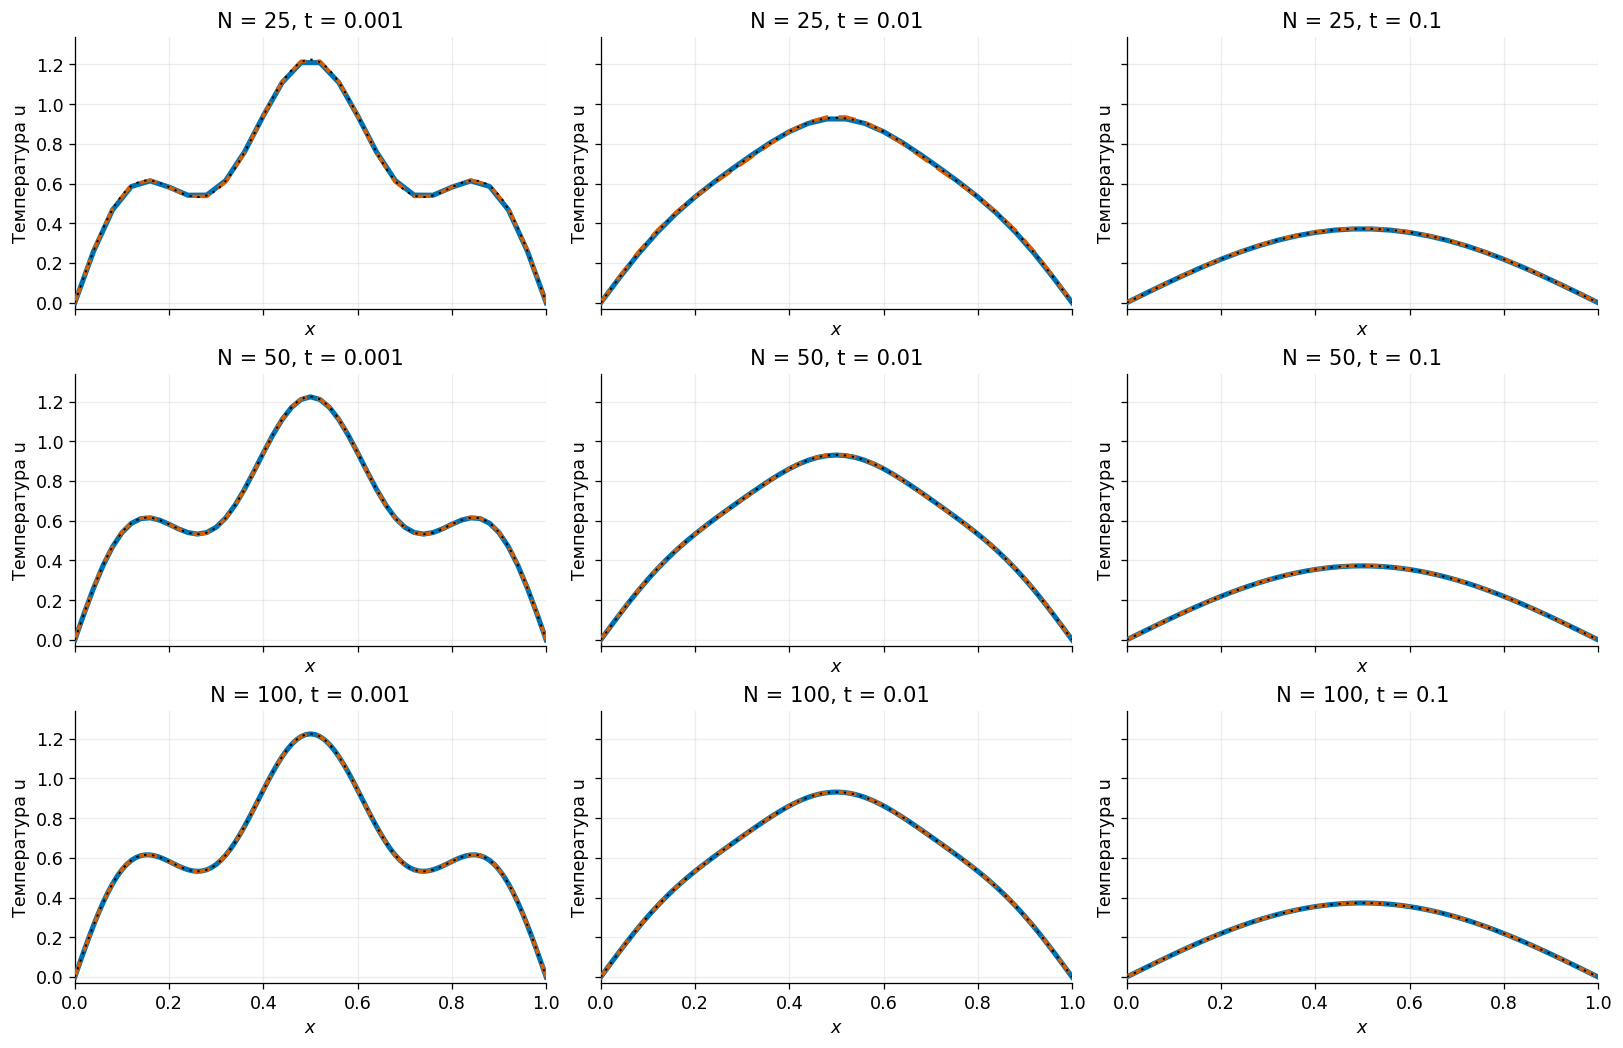

In [4]:
sizes = [25, 50, 100]
smooth_runs = {(method, N, t): heat_solve(N, 0.4, t, method)
               for method in ['FTCS', 'BE'] for N in sizes for t in target_times}
fig, axes = plt.subplots(3, 3, figsize=(14, 9), sharex=True, sharey=True,
                         layout='constrained')
for row, N in enumerate(sizes):
    for col, t in enumerate(target_times):
        ax = axes[row, col]
        for method in ['FTCS', 'BE']:
            plot_run(ax, smooth_runs[method, N, t], t)
        ax.plot(xx, cooling_exact(xx, t), **REFERENCE_STYLE, label='Точное решение')
        ax.set(xlim=(0, 1), ylim=(-0.03, 1.34), xlabel='$x$', ylabel='Температура u',
               title=f'N = {N}, t = {t:g}')
shared_legend(fig, axes[0, 0])
plt.show()

smooth_errors = {}
rows = []
for t in target_times:
    previous = {}
    for N in sizes:
        values = []
        for method in ['FTCS', 'BE']:
            run = smooth_runs[method, N, t]
            error = np.max(abs(run['u'][-1] - cooling_exact(run['x'], t)))
            smooth_errors[method, N, t] = error
            order = ('—' if method not in previous else
                     f'{np.log2(previous[method] / error):.3f}')
            previous[method] = error
            values.extend([f'{error:.5e}', order])
        rows.append([f'{t:g}', N] + values)
table(['t', 'N', r'$E_\infty$, FTCS', '$p_N$',
       r'$E_\infty$, неявный Эйлер', '$p_N$'], rows)

При сгущении сетки ошибки обоих методов уменьшаются. Например, при $t=0.01$ переход от $N=50$ к $100$ снижает ошибку FTCS с $7.62\cdot10^{-4}$ до $1.91\cdot10^{-4}$, а неявного Эйлера — с $1.86\cdot10^{-3}$ до $4.64\cdot10^{-4}$. Уменьшение почти в четыре раза соответствует ожидаемому второму порядку по $h$.

Для раннего момента $t=0.001$ оценки ниже: $1.62$ и $1.69$ при первом сгущении, около $1.94$ при втором. На сетках $N=25$, $50$, $100$ до этого времени выполняются соответственно 2, 7 и 25 шагов. Последние диффузионные числа равны $0.225$, $0.1$ и $0.4$. Поэтому временная ошибка на самых грубых сетках ещё не имеет одного и того же коэффициента при $h^2$. Кроме того, на длину волны пятой гармоники приходится всего 10 интервалов при $N=25$. Отклонение ранних оценок от двух здесь не означает изменения порядка схемы.

На общих профилях различия почти незаметны, поэтому отдельно построим **ошибку со знаком** $U_j-u_*(x_j,t)$ на грубой сетке. Она показывает, где схема завышает и где занижает температуру. Под ней приведена зависимость максимальной ошибки от $h$; вспомогательная прямая $h^2$ задаёт наклон, с которым сравниваются численные результаты.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), layout='constrained')
hs = 1 / np.array(sizes)
for col, t in enumerate(target_times):
    for method, marker in [('FTCS', 'o'), ('BE', 's')]:
        run = smooth_runs[method, 25, t]
        signed_error = run['u'][-1] - cooling_exact(run['x'], t)
        axes[0, col].plot(run['x'], signed_error, **STYLES[method],
                          label=LABELS[method])
        errors = [smooth_errors[method, N, t] for N in sizes]
        axes[1, col].loglog(hs, errors, marker=marker, **STYLES[method],
                            label=LABELS[method])
    axes[0, col].axhline(0, color='0.55', lw=0.8)
    axes[0, col].set(xlabel='$x$', ylabel=r'$U-u_*$', xlim=(0, 1),
                      title=f'Ошибка со знаком: N = 25, t = {t:g}')
    axes[0, col].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
    guide = 0.6 * smooth_errors['FTCS', 100, t] * (hs / hs[-1])**2
    axes[1, col].loglog(hs, guide, color='0.4', ls=':', lw=1.2,
                        label=r'$h^2$ (наклон)')
    axes[1, col].set(xlabel='Шаг сетки h', ylabel=r'$E_\infty$',
                      title=f'Сходимость при t = {t:g}, r = 0.4')
    axes[1, col].set_xticks(hs, ['1/25', '1/50', '1/100'])
    axes[1, col].xaxis.set_minor_formatter(NullFormatter())
shared_legend(fig, axes[1, 0])
plt.show()

При $t=0.1$ ошибка FTCS отрицательна почти во всех внутренних узлах, а ошибка неявного Эйлера положительна: первая схема немного занижает оставшуюся полуволну, вторая завышает. Причины связаны с двумя видами дискретизации. Центральная разность несколько замедляет затухание гармоник по сравнению с исходным уравнением. Явный Эйлер для этих гармоник, напротив, ускоряет затухание относительно точного решения системы на сетке, а неявный Эйлер дополнительно его замедляет. При выбранном $r=0.4$ пространственная и временная ошибки FTCS частично компенсируются. Поэтому её меньшая ошибка в этом опыте не является общим преимуществом явных схем.

## 3. Резкие края нагретого участка

### Схема Кранка—Николсона

Усредним пространственный оператор на старом и новом слоях:
$$\frac{U^{n+1}-U^n}{\tau_n}=\frac12L_hU^n+\frac12L_hU^{n+1}.$$
Для внутреннего узла получаем
$$-\frac{r_n}{2}U_{j-1}^{n+1}+(1+r_n)U_j^{n+1}
-\frac{r_n}{2}U_{j+1}^{n+1}
=\frac{r_n}{2}U_{j-1}^{n}+(1-r_n)U_j^n+\frac{r_n}{2}U_{j+1}^{n}.$$
Это уже реализованная общая схема с $\vartheta=1/2$. Симметричное усреднение по времени повышает порядок: для гладкого решения погрешность составляет $O(\tau^2+h^2)$.

Схема безусловно устойчива, но её веса справа при $r_n>1$ не все положительны. Поэтому доказательство сохранения диапазона температур через неотрицательность весов здесь применимо только при $r_n\le1$. Это достаточное условие; его нарушение ещё не означает, что в конкретном расчёте обязательно появится отрицательная температура.

Начальное распределение теперь имеет два разрыва:
$$u_0(x)=\begin{cases}
1,&0.4\le x\le0.6,\\
0,&\text{вне этого участка}.
\end{cases}$$
Фиксируем $N=100$ и $h=0.01$. Оба края включены, поэтому единице равен **21 узел**, от $j=40$ до $j=60$. Все методы начинаются с одного и того же массива.

| $r=\tau/h^2$ | $\tau$ | Исследуемые схемы |
|---:|---:|---|
| $0.4$ | $0.00004$ | FTCS, неявный Эйлер, Кранк—Николсон |
| $2$ | $0.0002$ | Неявный Эйлер, Кранк—Николсон |
| $10$ | $0.001$ | Неявный Эйлер, Кранк—Николсон |

Большие шаги к FTCS не применяем: они выходят за используемое условие устойчивости $r\le1/2$. Во всех расчётах сохраняются полученные значения температуры, без обрезания по нулю или единице.

### Проверка расчёта на малом шаге

Для сравнения используем Кранка—Николсона с $r_{\mathrm{ref}}=0.01$, то есть $\tau_{\mathrm{ref}}=10^{-6}$, на той же пространственной сетке. Проверим результат двумя способами: уменьшением временного шага вдвое и решением системы $U'=L_hU$ без временной дискретизации.

Собственные векторы $L_h$ во внутренних узлах — $\sin(m\pi x_j)$, а собственные значения равны
$$\lambda_{m,h}=-\frac4{h^2}\sin^2\frac{m\pi h}{2},\qquad m=1,\ldots,N-1.$$
После разложения начального массива по этим векторам каждый коэффициент умножается на $e^{\lambda_{m,h}t}$. Дискретное синус-преобразование выполняет это разложение, обратное преобразование восстанавливает температуры.

Такое решение точно по времени для системы на выбранной сетке. Оно не устраняет погрешность замены $u_{xx}$ центральной разностью. Поэтому последующее сравнение с малым шагом измеряет **временную ошибку при фиксированном $h$**, а не полную ошибку решения исходного уравнения с разрывными данными.

Проверка малого шага включает самые ранние слои, которые будут показаны ниже: $t=0.00004$ и $0.00008$ для $r=0.4$, $t=0.0002$ и $0.0004$ для $r=2$. Для сравнения **разных шагов между собой** используем общие физические моменты $t=0.001$, $0.002$, $0.004$, $0.01$. Все они совпадают с рассчитанными слоями соответствующих решений; интерполяция по времени не требуется.

In [ ]:
def semidiscrete_exact(initial, times):
    """Точное по времени решение U'=L_h U с тем же начальным массивом."""
    N = len(initial) - 1
    m = np.arange(1, N)
    eigenvalues = -4 * N**2 * np.sin(m * np.pi / (2 * N))**2
    coefficients = dst(initial[1:-1], type=1, norm='ortho')
    inner = idst(np.exp(np.outer(times, eigenvalues)) * coefficients,
                 type=1, norm='ortho', axis=-1)
    return np.pad(inner, ((0, 0), (1, 1)))


N_box = 100
end_time = 0.01
comparison_times = [0.001, 0.002, 0.004, 0.01]
box_runs = {(method, r): heat_solve(N_box, r, end_time, method, hot_section)
            for method in ['BE', 'CN'] for r in [0.4, 2.0, 10.0]}
box_runs['FTCS', 0.4] = heat_solve(N_box, 0.4, end_time, 'FTCS', hot_section)
reference = heat_solve(N_box, 0.01, end_time, 'CN', hot_section)
reference_finer = heat_solve(N_box, 0.005, end_time, 'CN', hot_section)
reference_check_times = [0.00004, 0.00008, 0.0002, 0.0004] + comparison_times
grid_exact = semidiscrete_exact(reference['u'][0], reference_check_times)

rows = []
for i, t in enumerate(reference_check_times):
    difference = np.max(abs(at_time(reference, t) - at_time(reference_finer, t)))
    exact_difference = np.max(abs(at_time(reference, t) - grid_exact[i]))
    rows.append([f'{t:g}', f'{difference:.3e}', f'{exact_difference:.3e}'])
    assert exact_difference < 9e-6
table(['t', 'Разность шагов r=0.01 и 0.005',
       'Ошибка малого шага относительно точного по времени решения'], rows)

На самом раннем из проверенных слоёв ошибка малого шага равна $8.49\cdot10^{-6}$. К $t=0.001$ она уменьшается до $2.52\cdot10^{-8}$, а к $t=0.01$ — до $4.59\cdot10^{-10}$. Для рассматриваемых крупных шагов различия будут значительно больше. Сильная зависимость ошибки от времени ожидаема: резкий начальный профиль содержит быстро затухающие гармоники, и первые слои наиболее требовательны к временному разрешению.

### Первые два слоя

Для каждого $r$ рассмотрим первый и второй шаги. В пределах одной панели обе неявные схемы и расчёт на малом шаге показаны в один физический момент; для $r=0.4$ добавлена FTCS. Между строками времена различаются, поскольку длительность одного шага разная. Эти рисунки показывают поведение схем при старте. Сравнение разных $r$ в одинаковые моменты времени приведено отдельно ниже.

В таблице после рисунка выпишем экстремумы первого слоя и разность соседних температур
$$D(t)=U_{40}(t)-U_{39}(t)=U(0.40,t)-U(0.39,t).$$
Изначально $D(0)=1$. При физическом сглаживании температура около левого края возрастает в сторону центра участка, так что $D(t)$ остаётся положительной. Отрицательное значение $D$ выявляет обратный перепад между этими узлами, даже если все температуры остаются в диапазоне от нуля до единицы.

In [ ]:
rs = [0.4, 2.0, 10.0]
fig, axes = plt.subplots(3, 2, figsize=(13, 9.4), sharex=True, sharey=True,
                         layout='constrained')
for row, r in enumerate(rs):
    for col, layer in enumerate([1, 2]):
        t = layer * box_runs['CN', r]['dt']
        methods = ['FTCS', 'BE', 'CN'] if r == 0.4 else ['BE', 'CN']
        for method in methods:
            plot_run(axes[row, col], box_runs[method, r], t)
        plot_small_step(axes[row, col], t)
        axes[row, col].set(xlim=(0, 1), ylim=(-0.04, 1.04),
                            xlabel='$x$', ylabel='Температура u',
                            title=f'r = {r:g}, слой {layer}, t = {t:g}')
shared_legend(fig, axes[0, 0])
plt.show()

rows = []
for r in rs:
    methods = ['FTCS', 'BE', 'CN'] if r == 0.4 else ['BE', 'CN']
    for method in methods:
        run = box_runs[method, r]
        u = run['u'][1]
        rows.append([f'{r:g}', f"{run['times'][1]:g}", LABELS[method],
                     f'{u.min():.3e}', f'{u.max():.9f}', f'{u[40]-u[39]:+.6f}'])
table(['r', 't первого слоя', 'Схема', 'Минимум', 'Максимум', '$D(t)$'], rows)

При $r=0.4$ у всех трёх схем перепад $D$ на первом слое положителен. У Кранка—Николсона при $r=2$ он уже равен примерно $-0.106$, при $r=10$ — $-0.564$. Таким образом, искусственное колебание возникает уже при среднем из выбранных шагов; позже оно быстро ослабевает и на графиках при $t\ge0.001$ заметно гораздо меньше.

При $r=10$ схема Кранка—Николсона после первого шага даёт $U(0.39)\approx0.782$, $U(0.40)\approx0.218$: узел снаружи нагретого участка оказывается горячее соседнего узла внутри. После второго шага значения составляют примерно $0.207$ и $0.791$. Перепад меняет знак, а величина колебания убывает медленно. Неявный Эйлер и расчёт на малом шаге дают плавный переход без такого обращения профиля.

Увеличенные фрагменты первого слоя показывают оба края. Горизонтальные окна имеют одинаковую ширину, вертикальный масштаб общий. Около правого края картина зеркальная, как и должно быть при симметричных начальных и граничных данных.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True, layout='constrained')
windows = [((0.34, 0.46), 'Левый край', 0.4),
           ((0.54, 0.66), 'Правый край', 0.6)]
for row, (window, name, edge) in enumerate(windows):
    for col, r in enumerate(rs):
        ax = axes[row, col]
        t = box_runs['CN', r]['dt']
        methods = ['FTCS', 'BE', 'CN'] if r == 0.4 else ['BE', 'CN']
        for method in methods:
            plot_run(ax, box_runs[method, r], t)
        plot_small_step(ax, t)
        ax.axvline(edge, color='0.7', ls=':', lw=1, zorder=1)
        ax.set(xlim=window, ylim=(-0.04, 1.04), xlabel='$x$', ylabel='Температура u',
               title=f'{name}: r = {r:g}, t = {t:g}')
        ticks = np.linspace(*window, 5)
        ax.set_xticks(ticks, [f'{value:.2f}' for value in ticks])
shared_legend(fig, axes[0, 0])
plt.show()

### Разные шаги в одинаковые моменты времени

Теперь фиксируем $t=0.001$ и $0.004$. При $r=0.4$ до них выполняются 25 и 100 шагов, при $r=2$ — 5 и 20, при $r=10$ — 1 и 4. Каждая строка рисунка соответствует одной стадии остывания стержня; различия между столбцами обусловлены выбором шага.

При $r=0.4$ все схемы близки к расчёту на малом шаге. При $r=2$ колебание Кранка—Николсона заметно на раннем профиле, но к $t=0.004$ почти исчезает. При $r=10$ зубцы около краёв сохраняются. Профиль неявного Эйлера при увеличении шага остаётся плавным, однако заметно отличается от уточнённого решения: отсутствие колебаний также не означает высокой точности.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True,
                         layout='constrained')
for row, t in enumerate([0.001, 0.004]):
    for col, r in enumerate([0.4, 2.0, 10.0]):
        ax = axes[row, col]
        methods = ['FTCS', 'BE', 'CN'] if r == 0.4 else ['BE', 'CN']
        for method in methods:
            plot_run(ax, box_runs[method, r], t)
        plot_small_step(ax, t)
        ax.set(xlim=(0.25, 0.75), ylim=(-0.04, 1.04), xlabel='$x$', ylabel='Температура u',
               title=f'r = {r:g}, t = {t:g}')
shared_legend(fig, axes[0, 0])
plt.show()

Введём максимальное отличие от расчёта на малом шаге:
$$E_{\tau,h}(t)=\max_j|U_j(t)-U_j^{\mathrm{ref}}(t)|.$$
Пространственная сетка здесь одна и та же, $h=0.01$. Погрешность самого эталона в этих четырёх моментах меньше $3\cdot10^{-8}$, поэтому её вклад в приведённые ниже ошибки мал.

При $t=0.001$, $r=10$ ошибка неявного Эйлера равна $0.0621$, а Кранка—Николсона — $0.327$, то есть более чем в пять раз больше. При $t=0.01$ получаем соответственно $0.0138$ и $0.0784$. Более высокий формальный порядок Кранка—Николсона не обеспечивает преимущества на столь крупном шаге из разрывного начального состояния.

Для малого шага ситуация иная. При $r=0.4$, $t=0.01$ ошибки равны $5.52\cdot10^{-4}$ и $7.35\cdot10^{-7}$. В этом режиме Кранк—Николсон значительно точнее. Уменьшение $r$ с $2$ до $0.4$ в тот же момент снижает ошибку неявного Эйлера примерно в 5 раз, а Кранка—Николсона — в 25 раз. Это согласуется с первым и вторым порядками по времени при фиксированном пространственном шаге. Для первых крупных шагов из разрыва такая асимптотическая зависимость ещё не выполняется.

In [ ]:
step_errors = {}
for method in ['BE', 'CN']:
    for r in [0.4, 2.0, 10.0]:
        for t in comparison_times:
            step_errors[method, r, t] = np.max(
                abs(at_time(box_runs[method, r], t) - at_time(reference, t)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True, layout='constrained')
time_colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7']
rs = [0.4, 2.0, 10.0]
for ax, method in zip(axes, ['BE', 'CN']):
    for t, color, marker in zip(comparison_times, time_colors, ['o', 's', '^', 'D']):
        errors = [step_errors[method, r, t] for r in rs]
        ax.loglog(rs, errors, marker=marker, color=color, lw=2, label=f't = {t:g}')
    ax.set(xlabel=r'$r=\tau/h^2$', ylabel=r'$E_{\tau,h}$', title=LABELS[method])
    ax.set_xticks(rs, ['0.4', '2', '10'])
    ax.xaxis.set_minor_formatter(NullFormatter())
shared_legend(fig, axes[0])
plt.show()

rows = []
for t in [0.001, 0.01]:
    for r in rs:
        rows.append([f'{t:g}', f'{r:g}',
                     f"{step_errors['BE', r, t]:.5e}",
                     f"{step_errors['CN', r, t]:.5e}"])
table(['t', 'r', r'$E_{\tau,h}$, неявный Эйлер',
       r'$E_{\tau,h}$, Кранк—Николсон'], rows)

### Экстремумы и колебания около края

Минимум и максимум вычисляем по всем узлам на каждом временном слое:
$$u_{\min}(t_n)=\min_j U_j^n,\qquad u_{\max}(t_n)=\max_j U_j^n.$$
В проведённых расчётах температуры не становятся отрицательными и не превышают единицу. Глобальный минимум равен нулю из-за холодных концов стержня, максимум постепенно убывает. Поэтому по одним экстремумам колебания около края здесь обнаружить нельзя.

В нижней строке показан перепад $D(t)=U_{40}(t)-U_{39}(t)$ на начальном промежутке $0\le t\le0.004$. Отрицательные участки соответствуют обращению температурного профиля на паре соседних узлов. При $r=2$ такое обращение у Кранка—Николсона быстро исчезает, при $r=10$ знак чередуется на последовательных слоях. Расчёт на малом шаге остаётся положительным. Линии соединяют рассчитанные значения; внутри крупного временного шага новых данных нет.

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 8.6), sharey='row',
                         gridspec_kw={'height_ratios': [0.65, 1, 1.15]},
                         layout='constrained')
reference_curves = [reference['u'].min(axis=1), reference['u'].max(axis=1),
                    reference['u'][:, 40] - reference['u'][:, 39]]
for col, r in enumerate(rs):
    methods = ['FTCS', 'BE', 'CN'] if r == 0.4 else ['BE', 'CN']
    for method in methods:
        run = box_runs[method, r]
        curves = [run['u'].min(axis=1), run['u'].max(axis=1),
                  run['u'][:, 40] - run['u'][:, 39]]
        for row, values in enumerate(curves):
            axes[row, col].plot(run['times'], values, **STYLES[method],
                                label=LABELS[method])
    for row, values in enumerate(reference_curves):
        axes[row, col].plot(reference['times'], values, **REFERENCE_STYLE,
                            label='Малый шаг')
    for row, label, limits, t_limit in [
        (0, 'Минимум u', (-0.01, 0.01), end_time),
        (1, 'Максимум u', (0.5, 1.03), end_time),
        (2, r'$D(t)=U_{40}-U_{39}$', (-0.65, 1.04), 0.004),
    ]:
        axes[row, col].set(ylabel=label, ylim=limits, xlabel='t', xlim=(0, t_limit))
        axes[row, col].ticklabel_format(axis='x', style='sci', scilimits=(0, 0))
    axes[2, col].axhline(0, color='0.55', lw=0.8, zorder=1)
    axes[0, col].set_title(f'r = {r:g}, N = 100')
shared_legend(fig, axes[0, 0])
plt.show()

## 4. Почему устойчивое решение может колебаться

Каждая дискретная гармоника удовлетворяет отдельному уравнению $a'=\lambda_{m,h}a$. Для одного шага введём $s=-\lambda_{m,h}\tau\ge0$. Точный множитель затухания равен $e^{-s}$, а подстановка в разностные схемы даёт
$$G_{\mathrm{FTCS}}=1-s,\qquad
G_{\mathrm{BE}}=\frac1{1+s},\qquad
G_{\mathrm{CN}}=\frac{1-s/2}{1+s/2}.$$

У обеих неявных схем $|G|\le1$ при любом $s\ge0$. Дискретные гармоники ортогональны, поэтому ни одна их комбинация не увеличивает норму
$$\|U\|_h=\left(h\sum_{j=1}^{N-1}U_j^2\right)^{1/2}.$$
В этом смысле обе схемы безусловно устойчивы. Однако неравенство для нормы ничего не говорит о близости $G$ к точному множителю или о знаке $G$.

У Кранка—Николсона при $s>2$ множитель отрицателен: соответствующая составляющая меняет знак на каждом шаге. Более того, при $s\to\infty$ он стремится к $-1$. Быстрые гармоники, которые точное решение должно почти полностью погасить за один шаг, численно сохраняются с чередующимся знаком. У неявного Эйлера $G$ положителен и стремится к нулю, поэтому эти гармоники подавляются гораздо сильнее. При этом $1/(1+s)>e^{-s}$: неявный Эйлер тоже затухает медленнее точного решения системы, а не точнее воспроизводит каждый режим.

Для самой высокой гармоники на сетке $N=100$, $m=99$, при $r=10$ получаем $s\approx39.99$. Точный множитель — около $4.3\cdot10^{-18}$, у неявного Эйлера — $0.0244$, у Кранка—Николсона — $-0.905$. Начальный прямоугольный профиль содержит эту гармонику, так что после крупного шага её ложный вклад остаётся заметным.

На правом графике коэффициент этой гармоники извлечён из рассчитанных профилей синус-преобразованием и разделён на начальное значение. Он совпадает с предсказанием $G^n$. Отрицательный коэффициент отдельной гармоники не означает отрицательной температуры: температура складывается из всех составляющих. Это объясняет наблюдаемые зубцы при отсутствии отрицательных значений полного решения.

In [ ]:
# Убывание нормы проверяем на всех рассчитанных слоях.
for run in box_runs.values():
    norm_squared = run['h'] * np.sum(run['u'][:, 1:-1]**2, axis=1)
    assert np.max(np.diff(norm_squared)) < 1e-12

s = np.linspace(0, 40, 801)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
axes[0].plot(s, np.exp(-s), **REFERENCE_STYLE, label='$e^{-s}$')
axes[0].plot(s, 1 / (1 + s), **STYLES['BE'], label=LABELS['BE'])
axes[0].plot(s, (1 - s / 2) / (1 + s / 2), **STYLES['CN'], label=LABELS['CN'])
axes[0].axhline(0, color='0.6', lw=1)
axes[0].axvline(2, color='0.6', ls=':', lw=1)
axes[0].set(xlabel=r'$s=-\lambda_h\tau$', ylabel='Множитель за шаг',
             ylim=(-1.05, 1.05), title='Затухание одной гармоники')
m = N_box - 1
layer_numbers = np.arange(7)
tau_large = box_runs['CN', 10.0]['dt']
lam = -4 * N_box**2 * np.sin(m * np.pi / (2 * N_box))**2
initial_coefficient = dst(reference['u'][0, 1:-1], type=1, norm='ortho')[m - 1]
assert abs(initial_coefficient) > 1e-8
for method, marker in [('BE', 's'), ('CN', 'o')]:
    run = box_runs[method, 10.0]
    coefficients = dst(run['u'][:7, 1:-1], type=1, norm='ortho', axis=1)[:, m - 1]
    measured = coefficients / initial_coefficient
    sn = -lam * tau_large
    gain = 1 / (1 + sn) if method == 'BE' else (1 - sn / 2) / (1 + sn / 2)
    assert np.max(abs(measured - gain**layer_numbers)) < 1e-12
    axes[1].plot(layer_numbers, measured, marker=marker, **STYLES[method], label=LABELS[method])
axes[1].plot(layer_numbers, np.exp(lam * tau_large * layer_numbers),
               **REFERENCE_STYLE, label='Точное решение системы ОДУ')
axes[1].axhline(0, color='0.6', lw=1)
axes[1].set(xlabel='Номер слоя n', ylabel=r'$a_{99}^n/a_{99}^0$',
             title='Высокая мода: N = 100, r = 10', ylim=(-1.05, 1.05))
axes[1].set_xticks(layer_numbers)
fig.legend(*axes[1].get_legend_handles_labels(), loc='outside upper center',
           ncol=3, fontsize=10)
plt.show()

rows = []
for r in rs:
    s_high = 4 * r * np.sin(m * np.pi / (2 * N_box))**2
    rows.append([f'{r:g}', f'{np.exp(-s_high):.3e}', f'{1 / (1 + s_high):.6f}',
                 f'{(1 - s_high / 2) / (1 + s_high / 2):+.6f}'])
table(['r', 'Точное затухание моды за шаг', '$G$, неявный Эйлер',
       '$G$, Кранк—Николсон'], rows)

## 5. Выводы

**Гладкое остывание.** FTCS и неявный Эйлер сходятся ко второму порядку по $h$ при связи $\tau=0.4h^2$: при $t=0.1$ последние оценки равны $2.001$ и $1.999$. Это результат совместного уточнения сетки и шага времени. При одинаковом $r=0.4$ FTCS в рассмотренных опытах точнее неявного Эйлера. Исчезновение пятой гармоники обусловлено уравнением теплопроводности: её скорость затухания в 25 раз больше, чем у первой.

**Остывание нагретого участка.** У Кранка—Николсона искусственный обратный перепад у края возникает уже при $r=2$, но быстро ослабевает. При $r=10$ он велик и сохраняется на нескольких слоях. Все температуры при этом лежат между нулём и единицей, поэтому проверку глобального минимума и максимума необходимо дополнять просмотром профиля. Неявный Эйлер сохраняет плавную форму, но при увеличении шага также теряет точность.

**Выбор шага.** При $t=0.001$, $r=10$ ошибка Кранка—Николсона относительно малого шага составляет $0.327$, неявного Эйлера — $0.0621$. При $r=0.4$, $t=0.01$ соотношение меняется: $7.35\cdot10^{-7}$ против $5.52\cdot10^{-4}$. Среди проверенных вариантов на данной сетке Кранк—Николсон с $r=0.4$ даёт наименьшую временную ошибку в выбранные общие моменты. Для резких начальных данных крупный шаг нельзя выбирать только по условию устойчивости.

Таким образом, **безусловная устойчивость не гарантирует ни точности, ни отсутствия осцилляций**. Она ограничивает рост нормы решения. Точность требует правильного воспроизведения затухания гармоник, а для отсутствия колебаний существенны также знаки их численных множителей. На фиксированной сетке уменьшение временного шага исправляет эти различия, но сохраняющаяся пространственная ошибка в такой проверке не измеряется.

Материалы курса: [условие задания 7.1](https://github.com/yartmihant/Students6Year2026/blob/86251f18f04ea2ce16506d96d6735db483c78e02/README.md), [теоретический конспект](https://github.com/yartmihant/Students6Year2026/blob/86251f18f04ea2ce16506d96d6735db483c78e02/lesson7/lesson_07_theory.md), [пример расчёта теплопроводности](https://github.com/yartmihant/Students6Year2026/blob/86251f18f04ea2ce16506d96d6735db483c78e02/lesson7/lesson_07_heat.ipynb), [дискретные гармоники и устойчивость](https://github.com/yartmihant/Students6Year2026/blob/86251f18f04ea2ce16506d96d6735db483c78e02/lesson7/lesson_07_diffusion_spectral.ipynb).